# P1.1 — What MRI Measures: spins, magnetization, resonance and relaxation

**Part:** Pass 1 — The big picture (notebook 1 of 5) · **Reading time:** ~40 min · **Next:** [P1.2 The MRI Scanner](P1.2_The_MRI_Scanner.ipynb) · **Refreshers you may want:** [Precession & torque](../refreshers/RP3_Precession_and_Torque.ipynb), [Spin & thermal statistics](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb), [Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb)

**Why this notebook matters.** Every MRI image, whatever its contrast or speed, is a map of one thing: the tiny
magnetism of hydrogen nuclei in your body and how it behaves after we disturb it with a radio wave. If you understand
four words — **polarization**, **resonance**, **excitation** and **relaxation** — plus how the resulting signal is
picked up by an antenna, you understand what MRI *measures*. The rest of Pass 1 explains how the scanner turns this
measurement into an image (P1.2–P1.3), what makes tissues look different (P1.4) and how it is made fast and safe (P1.5).

This Pass-1 series is deliberately light on mathematics. Every symbol is still defined, and every section ends with
**➡️ Go deeper** links to the Pass-2 chapter that does the full derivation.

## Learning goals

After this notebook you should be able to

1. Explain what a nuclear **spin** is and why MRI almost always images hydrogen (¹H).
2. Explain **polarization**: why a strong field $B_0$ creates a tiny but measurable **net magnetization** $\vec M$ — with numbers (≈ 10 ppm at 3 T).
3. Describe **precession** and **resonance**, and compute the **Larmor frequency** $f_0 = \bar\gamma B_0$ (127.7 MHz at 3 T).
4. Describe **excitation** by an RF pulse and the **flip angle** $\theta$.
5. Describe **relaxation** with the time constants $T_1$, $T_2$ and $T_2^*$, and what a **spin echo** does.
6. Explain how a precessing magnetization induces a voltage (the MRI **signal**) in a receive coil.

## Symbols used in this notebook

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $x, y, z$ | position coordinates; $z$ is along the main field (the bore axis) | m | |
| $t$ | time | s | |
| $\vec B$ | magnetic flux density, "magnetic field" | T (tesla) | Earth ≈ 50 µT; fridge magnet ≈ 5 mT |
| $B_0$ | strength of the main static field (along $z$) | T | 0.55, 1.5, 3, 7 T |
| $B_1$ | strength of the radio-frequency (RF) magnetic field used for excitation | T | 1–25 µT |
| $b_1(t)$ | RF field written as a complex number $B_{1,x}+iB_{1,y}$ in the rotating frame | T | |
| $\vec\mu$ | magnetic moment of one nucleus ("tiny bar magnet") | J/T | ¹H: $1.41\times10^{-26}$ J/T |
| $I$ | spin quantum number of a nucleus | – | ½ for ¹H |
| $\gamma$ | gyromagnetic ratio (angular form) | rad s⁻¹ T⁻¹ | $2.675\times10^8$ for ¹H |
| $\bar\gamma=\gamma/2\pi$ | gyromagnetic ratio ("gamma-bar") | Hz/T | 42.58 MHz/T for ¹H |
| $f_0=\bar\gamma B_0$ | Larmor (resonance) frequency | Hz | 63.9 MHz @ 1.5 T, 127.7 MHz @ 3 T |
| $\omega_0=\gamma B_0 = 2\pi f_0$ | angular Larmor frequency | rad/s | |
| $h$, $\hbar=h/2\pi$ | Planck constant, reduced Planck constant | J s | $6.626\times10^{-34}$ J s |
| $k_B$ | Boltzmann constant | J/K | $1.381\times10^{-23}$ |
| $T$ (no subscript) | absolute temperature (do not confuse with the unit T = tesla or with $T_1, T_2$) | K | 310 K (body) |
| $\Delta E$ | energy gap between the two spin states, $\Delta E = h\bar\gamma B_0$ | J | $8.5\times10^{-26}$ J at 3 T |
| $N$ | spin density: number of ¹H nuclei per volume | m⁻³ | water: $6.7\times10^{28}$ m⁻³ |
| $N_\uparrow$, $N_\downarrow$ | number of spins in the lower ("parallel") / upper ("anti-parallel") energy state | – | |
| $\vec M=[M_x,M_y,M_z]^T$ | net magnetization = sum of all nuclear moments per volume | A/m (we normalize $M_0=1$) | |
| $M_0$ | equilibrium magnetization (its size when nothing disturbs it) | A/m | ≈ 0.009 A/m for water at 3 T |
| $M_z$ | longitudinal magnetization (component along $B_0$) | same as $M$ | |
| $M_{xy}=M_x+iM_y$ | transverse magnetization written as a complex number ($i=\sqrt{-1}$) | same as $M$ | this is what produces signal |
| $\theta$ | flip angle: how far the RF pulse tips $\vec M$ away from $z$ | rad or ° | 90°, 180°, small angles 5–30° |
| $T_{rf}$ | duration of the RF pulse | s | 0.1–10 ms |
| $\Delta f$ | off-resonance: difference between a spin's precession frequency and the reference frequency | Hz | |
| $T_1$ | longitudinal relaxation **time constant** (regrowth of $M_z$) | s | 0.25–4 s |
| $T_2$ | transverse relaxation **time constant** (decay of $M_{xy}$) | s | 10 ms – 2 s |
| $T_2^*$ | effective transverse decay time incl. field inhomogeneity, $T_2^*\le T_2$ | s | |
| $T_2'$ | dephasing time due to field inhomogeneity alone, $1/T_2^* = 1/T_2 + 1/T_2'$ | s | |
| $TE$ | echo time (excitation → echo/measurement) | s | 1–100 ms |
| $s(t)$ | received signal (voltage in the coil) | V | µV range |
| $\mu_0$ | vacuum permeability | T m/A | $4\pi\times10^{-7}$ |

**Symbol clash warning:** $T$ alone is temperature; "T" after a number is the unit tesla; $T_1$, $T_2$ are relaxation times.
"ppm" = parts per million = $10^{-6}$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline

## 1. The big idea in one paragraph

Your body is ~60 % water, and each water molecule has two hydrogen nuclei (protons). Each proton behaves like a
**tiny spinning bar magnet**. Put the body into a very strong magnet ($B_0$ = 1.5 or 3 T, i.e. 30 000–60 000 × Earth's
field) and a small surplus of these magnets lines up with the field: the body becomes very weakly magnetized
(**polarization**). The magnetization can be tipped over by a short radio wave at exactly the right frequency
(**resonance**, **excitation**). Once tipped, it spins around the field direction like a wobbling top (**precession**),
and a rotating magnet induces a voltage in a nearby wire loop — the **MRI signal**. Over tens of milliseconds to
seconds the magnetization returns to its resting state (**relaxation**), and *how fast* it does so depends on the tissue.
That dependence is the main source of the beautiful soft-tissue contrast of MRI.

![The fundamental MRI experiment](../images/MRI_experiment_diagram.png)

*The MRI experiment: polarize (main magnet) → excite (RF transmit coil) → acquire signal (RF receive coil), with spatial
encoding by gradient coils, repeated as needed. (Figure from Larson, Principles of MRI.)*

## 2. Nuclear spin: every proton is a tiny magnet

A **nuclear spin** is a nucleus with non-zero angular momentum ("it spins"). Because the nucleus is charged and spinning,
it also has a **magnetic moment** $\vec\mu$: it acts like a microscopic compass needle. The spin quantum number $I$
describes how many orientations the spin can take in a field; for ¹H, $I=\tfrac12$ (two states, "up" and "down").

> **🧭 Intuition:** Think of each proton as a **spinning top that is also a compass needle**. Being a compass needle means
> a magnetic field pulls on it; being a spinning top means it does not simply flip over to align, it *wobbles* around the
> field instead (precession, Section 4).

Why hydrogen?

* **Abundance:** hydrogen nuclei are ~2/3 of all atoms in the body (mostly in water, also in fat).
* **Strong magnet:** ¹H has the largest gyromagnetic ratio $\bar\gamma$ of all stable nuclei (42.58 MHz/T), which gives
  the most signal.

Other nuclei with spin (¹³C, ¹⁹F, ²³Na, ³¹P, ¹²⁹Xe) are imaged in research, but they are far less abundant or weaker
and need special RF hardware tuned to their frequency.

> **⚠️ Common confusion:** "Nuclear" in nuclear magnetic resonance has nothing to do with radioactivity. MRI uses no
> ionizing radiation; the "radio" waves are of the same kind as FM radio.

➡️ **Go deeper:** [A1 Spin Physics](../pass2_deep_dive/A1_Spin_Physics.ipynb) · refresher [RP4 Spin & thermal statistics](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb)

## 3. Polarization: a tiny surplus of aligned spins

Without a field, the spins point in random directions and cancel: no net magnetism (left image). In a field $B_0$
pointing along $z$, the "up" state (parallel to $B_0$) has slightly lower energy than the "down" state. The energy gap is

$$\Delta E = h\,\bar\gamma\,B_0 .$$

*In words:* the stronger the field, the bigger the energy difference between the two orientations.
Here $h$ is Planck's constant, $\bar\gamma$ the gyromagnetic ratio [Hz/T], $B_0$ the field [T].

Body heat (thermal energy $k_B T$, with $k_B$ Boltzmann's constant and $T \approx 310$ K) constantly kicks the spins
around, and $\Delta E$ is *tiny* compared to $k_B T$. So the populations differ only slightly (Boltzmann statistics):

$$\text{polarization}=\frac{N_\uparrow-N_\downarrow}{N_\uparrow+N_\downarrow}\approx\frac{h\bar\gamma B_0}{2k_BT}.$$

*In words:* the fraction of "surplus" spins that actually contribute to the signal grows linearly with $B_0$ and
falls with temperature. $N_\uparrow$, $N_\downarrow$ are the numbers of spins in the lower and upper state.

| ![Spins without a field](../images/MagSpherical2.jpg) | ![Spins in a field](../images/MagPrecession2.jpg) |
| :-: | :-: |
| No field: random orientation, no net magnetization | In a field (vertical): slightly more spins point "up"; their sum is the **net magnetization** (big arrow) |

*Images: DRCMR, https://www.drcmr.dk/mr*

Let's put in numbers.

In [2]:
T_body = 310.0                     # body temperature [K]
N_water = 6.7e28                   # 1H nuclei per m^3 in water (2 H per molecule)
B0_list = np.array([0.55, 1.5, 3.0, 7.0])   # typical clinical / research fields [T]

dE = mt.H_PLANCK * mt.GAMMA_BAR * B0_list               # energy gap [J]
x = dE / (mt.K_BOLTZMANN * T_body)                      # ratio  Delta E / (k_B T)
polarization = np.tanh(x / 2)                           # exact for spin-1/2: (1-e^-x)/(1+e^-x)

voxel = 1e-9                                            # a 1 mm^3 voxel [m^3]
for B0, p in zip(B0_list, polarization):
    print(f"B0 = {B0:4.2f} T : polarization = {p*1e6:5.1f} ppm   -> surplus spins in 1 mm^3 = {p*N_water*voxel:.1e}")
print(f"\nThermal energy k_B T = {mt.K_BOLTZMANN*T_body:.2e} J  vs  Delta E(3 T) = {dE[2]:.2e} J  (ratio {x[2]:.1e})")

B0 = 0.55 T : polarization =   1.8 ppm   -> surplus spins in 1 mm^3 = 1.2e+14
B0 = 1.50 T : polarization =   4.9 ppm   -> surplus spins in 1 mm^3 = 3.3e+14
B0 = 3.00 T : polarization =   9.9 ppm   -> surplus spins in 1 mm^3 = 6.6e+14
B0 = 7.00 T : polarization =  23.1 ppm   -> surplus spins in 1 mm^3 = 1.5e+15

Thermal energy k_B T = 4.28e-21 J  vs  Delta E(3 T) = 8.46e-26 J  (ratio 2.0e-05)


So at 3 T only about **10 out of every million** protons are "surplus" spins — but a single cubic millimetre of water
contains ~$7\times10^{19}$ protons, so the surplus is still ~$7\times10^{14}$ spins. Tiny fraction, huge number.

The sum of the surplus moments per unit volume is the **equilibrium magnetization** $M_0$. For spin-½ nuclei:

$$M_0=\frac{N\,\gamma^2\hbar^2\,B_0}{4\,k_B T}.$$

*In words:* more protons ($N$), a stronger field ($B_0$) and a colder sample (smaller $T$) give more magnetization;
$\gamma$ enters squared (once for the size of each nuclear magnet, once for the energy gap). Here $\hbar = h/2\pi$ and
$\gamma = 2\pi\bar\gamma$. (The general formula, valid for any spin $I$, is $M_0 = N\gamma^2\hbar^2 I(I+1)B_0/(3k_BT)$;
with $I=\tfrac12$ it reduces to the line above.)

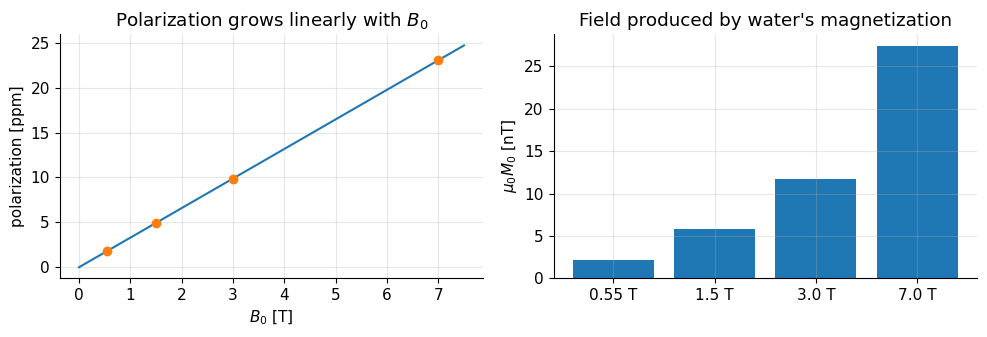

M0 of water at 3 T = 0.0093 A/m, i.e. mu0*M0 = 11.7 nT, about 4e-09 of B0


In [3]:
M0 = N_water * mt.GAMMA**2 * mt.HBAR**2 * B0_list / (4 * mt.K_BOLTZMANN * T_body)   # [A/m]

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
B = np.linspace(0, 7.5, 100)
ax[0].plot(B, np.tanh(mt.H_PLANCK*mt.GAMMA_BAR*B/(2*mt.K_BOLTZMANN*T_body)) * 1e6)
ax[0].plot(B0_list, polarization*1e6, "o")
ax[0].set_xlabel("$B_0$ [T]"); ax[0].set_ylabel("polarization [ppm]"); ax[0].set_title("Polarization grows linearly with $B_0$")
ax[1].bar([f"{b} T" for b in B0_list], mt.MU0 * M0 * 1e9)
ax[1].set_ylabel(r"$\mu_0 M_0$ [nT]"); ax[1].set_title("Field produced by water's magnetization")
plt.tight_layout(); plt.show()
print("M0 of water at 3 T = %.4f A/m, i.e. mu0*M0 = %.1f nT, about %.0e of B0" % (M0[2], mt.MU0*M0[2]*1e9, mt.MU0*M0[2]/3))

The body's magnetization at 3 T corresponds to a field of only ~12 nT — **250 million times weaker than $B_0$**.
We could never measure this directly next to a 3 T magnet. MRI's trick is to make this magnetization *rotate*, because
a rotating magnet produces an oscillating signal at a known frequency that we can tune into (Sections 4–7).

> **🔧 Engineering reality:** Signal ∝ $M_0$ ∝ $B_0$ is the main reason scanners got stronger (0.15 T in the early 1980s
> → 1.5 T → 3 T clinical, 7 T clinical-research, 11.7 T whole-body research magnets exist). Every doubling of $B_0$ roughly
> doubles the signal but also brings costs: price, weight, RF heating, artifacts (P1.2, P1.5). Low-field systems
> (0.05–0.55 T) are making a comeback because of cost, safety and portability, compensating with better electronics and
> reconstruction.

In MRI we almost always use the *normalized* magnetization $M_0 = 1$ (so $\vec M$ is "relative to its maximum").
At equilibrium $\vec M = [0,\,0,\,M_0]^T$: it points along $B_0$ and has no transverse part.

➡️ **Go deeper:** [A1 Spin Physics](../pass2_deep_dive/A1_Spin_Physics.ipynb) (polarization derivation) · [RP4 Spin & thermal statistics](../refreshers/RP4_Spin_and_Thermal_Statistics.ipynb) (Boltzmann distribution)

## 4. Precession and the Larmor frequency

If $\vec M$ is tilted away from $B_0$, the field exerts a twisting force (a **torque**) on it. A compass needle would
just swing into alignment; but a *spinning* magnet reacts to a torque like a spinning top in gravity: it **precesses**,
i.e. its axis circles around the field direction without falling over.

> **🧭 Intuition (spinning top):** a tilted top does not fall; its axis sweeps a cone around the vertical. Gravity's
> torque only makes the axis *move sideways*. In MRI, $B_0$ plays the role of gravity and $\vec M$ the role of the top's
> axis.

The precession frequency is exactly proportional to the field:

$$f_0 = \bar\gamma\,B_0 \qquad (\text{equivalently } \omega_0 = \gamma B_0,\ \omega_0 = 2\pi f_0).$$

*In words:* double the field and the spins precess twice as fast. $f_0$ is the **Larmor frequency** in Hz (cycles per
second), $\omega_0$ the same in rad/s, $\bar\gamma = 42.58$ MHz/T for ¹H.

> **⚠️ Common confusion:** $\gamma$ (rad s⁻¹ T⁻¹) vs $\bar\gamma=\gamma/2\pi$ (Hz/T) is the #1 source of factor-$2\pi$
> errors. Use $\bar\gamma$ with $f$ in Hz, and $\gamma$ with $\omega$ in rad/s.

In [4]:
print("Larmor frequencies f0 = gamma_bar * B0  [MHz]")
print("nucleus  gamma_bar[MHz/T]   0.55 T    1.5 T     3 T       7 T")
for nuc, gb in mt.GAMMA_BAR_NUCLEI.items():
    f = mt.larmor_frequency(B0_list, gb) / 1e6
    print(f"{nuc:6s}  {gb/1e6:9.3f}      " + "  ".join(f"{v:8.2f}" for v in f))
print("\nFor comparison: FM radio broadcasts at 87.5-108 MHz.")

Larmor frequencies f0 = gamma_bar * B0  [MHz]
nucleus  gamma_bar[MHz/T]   0.55 T    1.5 T     3 T       7 T
1H         42.577         23.42     63.87    127.73    298.04
2H          6.536          3.59      9.80     19.61     45.75
13C        10.708          5.89     16.06     32.12     74.96
19F        40.078         22.04     60.12    120.23    280.55
23Na       11.262          6.19     16.89     33.79     78.83
31P        17.235          9.48     25.85     51.70    120.64
129Xe     -11.777         -6.48    -17.67    -35.33    -82.44

For comparison: FM radio broadcasts at 87.5-108 MHz.


At 1.5 T protons "broadcast" at 63.9 MHz, at 3 T at 127.7 MHz — squarely in the radio band, hence **radio-frequency (RF)**
pulses and coils. (¹²⁹Xe has a negative $\bar\gamma$: it precesses the other way round.)

### Simulating precession

We use `mt.bloch_simulate`, which steps the **Bloch equation** (the equation of motion for $\vec M$, derived in A2).
Simulating 127.7 MHz would need nanosecond time steps, so we use a **scaled-down field** $B_0 = 2.35$ µT, giving a
leisurely $f_0 = 100$ Hz. The physics is identical, only slower. We start with $\vec M$ tilted by 30° from $z$.

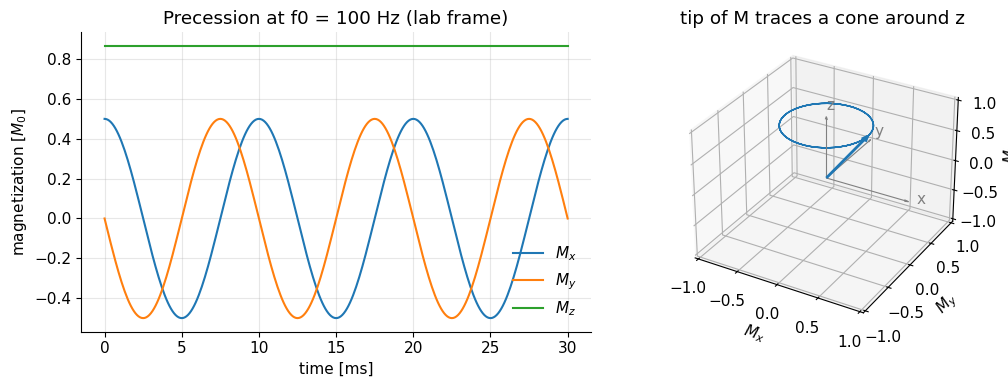

In [5]:
B0_toy = 100 / mt.GAMMA_BAR             # field that gives f0 = 100 Hz  [T]  (~2.35 uT)
tilt = np.deg2rad(30)
M_start = [np.sin(tilt), 0, np.cos(tilt)]
dt = 1e-4                               # time step: 0.1 ms
t, M = mt.bloch_simulate(n_steps=300, dt=dt, M_init=M_start, B0=B0_toy)   # lab frame, no relaxation

fig = plt.figure(figsize=(11, 4))
ax1 = fig.add_subplot(1, 2, 1)
mt.plot_magnetization(t, M, ax=ax1, title=f"Precession at f0 = {mt.GAMMA_BAR*B0_toy:.0f} Hz (lab frame)")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
mt.plot_magnetization_3d(M[:, 0, :], ax=ax2, title="tip of M traces a cone around z")
plt.tight_layout(); plt.show()

*Interpretation:* $M_z$ stays constant (the cone angle does not change), while $M_x$ and $M_y$ oscillate at 100 Hz,
a quarter-period apart: the vector circles the $z$-axis. Starting on $+x$, $M_y$ first goes *negative*: seen from above
(from $+z$) the vector moves from $+x$ towards $-y$, i.e. **clockwise**. This is the MRI convention: $M_{xy}(t) = M_{xy}(0)\,e^{-i\omega_0 t}$ with
$M_{xy}=M_x+iM_y$.

> **🔁 Refresher:** why a complex number $M_x + iM_y$ is a neat way to write a rotating 2D vector, and why
> $e^{-i\omega t}$ means clockwise rotation: [RM2 Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb).
> Why a torque produces precession rather than alignment: [RP3 Precession & torque](../refreshers/RP3_Precession_and_Torque.ipynb).

![Precessing magnetization induces a signal](../images/RF_reception.gif)

*Precessing magnetization (animation from Larson's book). The rotating magnet is what a receive coil detects (Section 7).*

> **⚠️ Common confusion:** Individual protons are quantum objects and are *not* simply "up" or "down" arrows sitting
> still. But the **net magnetization** $\vec M$ — the sum over ~$10^{19}$ spins per mm³ — behaves exactly like a classical
> spinning magnet. Everything in MRI imaging can be understood with the classical picture of $\vec M$.

➡️ **Go deeper:** [A2 Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb) · [RP3 Precession & torque](../refreshers/RP3_Precession_and_Torque.ipynb) · [RM2 Complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb)

## 5. Resonance and excitation: tipping $\vec M$ with a radio wave

At equilibrium $\vec M$ points along $z$, so it does not precess and produces no signal. To get a signal we must tip it.
We do this with a weak RF magnetic field $B_1$ (a few µT, a million times weaker than $B_0$!) applied
perpendicular to $B_0$ for a short time $T_{rf}$ — an **RF pulse**.

Why can such a weak field tip $\vec M$? **Resonance.**

> **🧭 Intuition (swing):** a child on a swing goes higher and higher if you push *in rhythm* with the swing, even with
> tiny pushes. Push at the wrong rhythm and nothing much happens. The RF field is the push; it must oscillate (rotate) at
> the Larmor frequency $f_0$ so that it stays "in step" with the precessing magnetization.

### The rotating frame

Watching $\vec M$ spin 128 million times per second while slowly tipping is confusing (left GIF). We therefore usually
describe things in the **rotating frame**: a coordinate system that itself rotates around $z$ at the RF frequency
(like watching a merry-go-round while riding on it). In this frame, an on-resonance RF field looks like a *static*
field along, say, $x$, and $\vec M$ simply rotates about it (right GIF).

| ![Lab frame](../images/RF_hard_lab_frame_on-resonance.gif) | ![Rotating frame](../images/RF_hard_rotating_frame_on-resonance.gif) |
| :-: | :-: |
| **Lab frame:** fast precession + slow tipping = spiral | **Rotating frame:** only the slow tipping remains |

In the rotating frame the spins only "feel" the part of the field that the frame's rotation does not cancel: the RF field
$b_1$ and any **off-resonance** $\Delta f$ (the difference between a spin's own precession frequency and the RF frequency,
expressed as an extra field $\Delta f/\bar\gamma$ along $z$). `mt.bloch_simulate` with `B0=0` (the default) works in this frame.

### The flip angle

On resonance, $\vec M$ rotates about the RF field direction at the rate $\gamma B_1$. A constant ("hard") pulse of
duration $T_{rf}$ therefore tips $\vec M$ by the **flip angle**

$$\theta = \gamma\, B_1\, T_{rf}.$$

*In words:* the tip angle is "rotation speed × time"; a stronger or longer pulse tips further. $\theta$ in rad,
$\gamma$ in rad s⁻¹ T⁻¹, $B_1$ in T, $T_{rf}$ in s. (For shaped pulses the product becomes an integral over $b_1(t)$, see E1.)

In [6]:
T_rf = 1e-3                                  # 1 ms pulse
for deg in [10, 30, 90, 180]:
    B1 = mt.b1_for_flip(np.deg2rad(deg), T_rf)
    print(f"flip {deg:3d} deg in 1 ms needs B1 = {B1*1e6:5.2f} uT   (B1/B0 at 3 T = {B1/3:.1e})")

flip  10 deg in 1 ms needs B1 =  0.65 uT   (B1/B0 at 3 T = 2.2e-07)
flip  30 deg in 1 ms needs B1 =  1.96 uT   (B1/B0 at 3 T = 6.5e-07)
flip  90 deg in 1 ms needs B1 =  5.87 uT   (B1/B0 at 3 T = 2.0e-06)
flip 180 deg in 1 ms needs B1 = 11.74 uT   (B1/B0 at 3 T = 3.9e-06)


Now the swing experiment. We apply the same 90° pulse (1 ms, $B_1 = 5.87$ µT along $x$) to many spins that differ only
in their off-resonance $\Delta f$ — equivalently, we detune the RF frequency away from the Larmor frequency by $\Delta f$
— and record how far each one gets tipped.

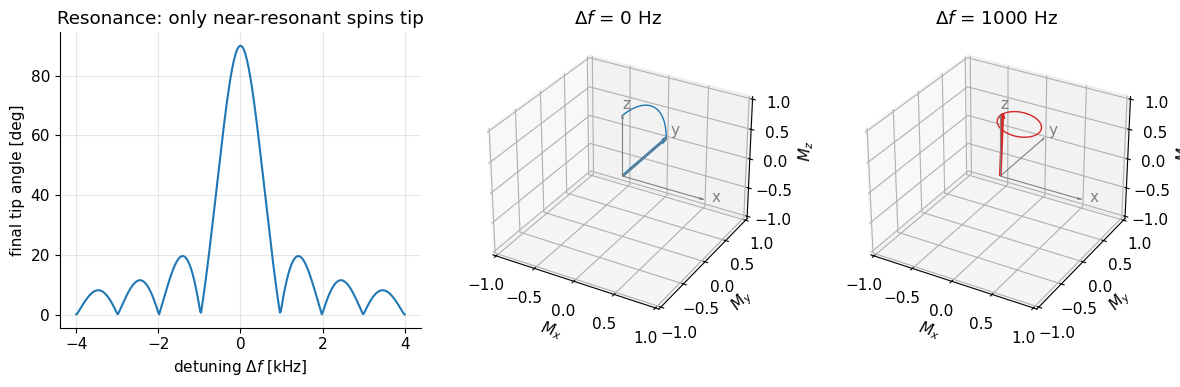

In [7]:
dt = 1e-6                                    # 1 us steps
n = int(T_rf / dt)
b1 = np.full(n, mt.b1_for_flip(np.pi/2, T_rf), dtype=complex)  # constant RF along +x (rotating frame)
df = np.linspace(-4000, 4000, 401)           # detuning of each spin [Hz]
t, M = mt.bloch_simulate(B1=b1, dt=dt, df=df)                  # M has shape (n+1, n_spins, 3)

tip = np.degrees(np.arccos(np.clip(M[-1, :, 2], -1, 1)))      # final angle from z
fig = plt.figure(figsize=(12, 4))
ax = fig.add_subplot(1, 3, 1)
ax.plot(df/1e3, tip); ax.set_xlabel(r"detuning $\Delta f$ [kHz]"); ax.set_ylabel("final tip angle [deg]")
ax.set_title("Resonance: only near-resonant spins tip")
for k, (j, c) in enumerate([(200, "C0"), (250, "C3")]):          # on resonance, and 1 kHz off
    a = fig.add_subplot(1, 3, 2 + k, projection="3d")
    mt.plot_magnetization_3d(M[:, j, :], ax=a, color=c, title=f"$\\Delta f$ = {df[j]:.0f} Hz")
plt.tight_layout(); plt.show()

*Interpretation:* on resonance the spin tips exactly 90° (middle). Only 1 kHz off resonance — less than 0.001 % of
127.7 MHz — the same pulse barely moves it and it just circles near the $z$-axis (right). The width of the resonance
peak is ≈ $1/T_{rf}$: a longer pulse is more frequency-selective. This selectivity is exactly what we will exploit for
**slice selection** in P1.3.

Common flip angles: **90°** puts all of $M_0$ into the transverse plane (maximum signal once); **180°** inverts
$M_z \to -M_0$ (used for inversion and spin echoes); **small angles** (5–30°) leave most magnetization along $z$ for
the next excitation (fast imaging).

| ![45° flip](../images/RF_45flip.gif) | ![90° flip](../images/RF_90flip.gif) | ![180° flip](../images/RF_180flip.gif) |
| :-: | :-: | :-: |
| 45° | 90° | 180° |

➡️ **Go deeper:** [A2 Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb) (lab vs rotating frame) · [E1 RF Pulses](../pass2_deep_dive/E1_RF_Pulses.ipynb) · [RP2 Induction & RF](../refreshers/RP2_Induction_and_RF.ipynb)

## 6. Relaxation: the way back to equilibrium ($T_1$, $T_2$, $T_2^*$)

After the RF pulse, $\vec M$ precesses, but it does not do so forever. Two independent processes return it to equilibrium:

* **$T_1$ relaxation (longitudinal, "spin–lattice")**: $M_z$ *regrows* towards $M_0$. The spins hand the absorbed RF
  energy to their surroundings (the "lattice"). Time constant $T_1$, typically 0.3–4 s.
* **$T_2$ relaxation (transverse, "spin–spin")**: $M_{xy}$ *decays* to zero, because neighbouring spins feel slightly
  different, randomly fluctuating fields and get out of step (lose phase coherence). No energy needs to leave.
  Time constant $T_2$, typically 10 ms – 2 s, and always $T_2 \le T_1$.

After a 90° pulse (so that $M_z(0)=0$ and $|M_{xy}(0)| = M_0$):

$$|M_{xy}(t)| = M_0\,e^{-t/T_2}, \qquad M_z(t) = M_0\,\bigl(1-e^{-t/T_1}\bigr).$$

*In words:* the transverse part decays exponentially with time constant $T_2$ (to 37 % after $t=T_2$); the longitudinal
part recovers exponentially with time constant $T_1$ (to 63 % of $M_0$ after $t=T_1$, 95 % after $3T_1$).
These are the solutions of simple first-order differential equations.

> **🔁 Refresher:** how $dM_z/dt = (M_0-M_z)/T_1$ leads to exponential recovery: [RM1 ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb).

> **⚠️ Common confusion:** $T_1$ and $T_2$ are **time constants** (seconds), not rates. The corresponding rates are
> $R_1 = 1/T_1$ and $R_2 = 1/T_2$ (s⁻¹). (The original book's notation table calls them "rates".)

![Relaxation](../images/relaxation_t1t2.gif)

The key point for imaging: **different tissues have different $T_1$ and $T_2$.** Water-rich, mobile tissue (CSF) relaxes
slowly; fat relaxes quickly. Let's look at approximate values at 3 T.

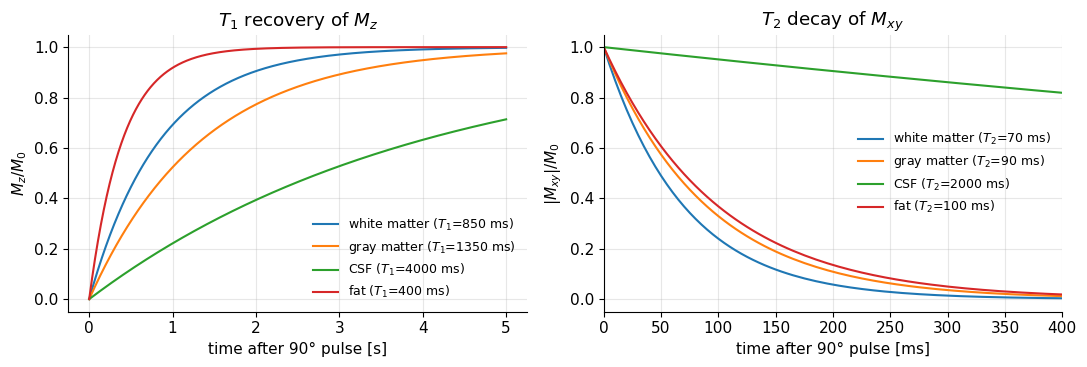

In [8]:
# Approximate relaxation times at 3 T [s]. Literature values vary by +-20-30 % between studies.
tissues = {"white matter": (0.85, 0.07), "gray matter": (1.35, 0.09), "CSF": (4.0, 2.0), "fat": (0.40, 0.10)}

t = np.linspace(0, 5, 1000)                       # [s]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name, (T1, T2) in tissues.items():
    ax[0].plot(t, 1 - np.exp(-t/T1), label=f"{name} ($T_1$={T1*1e3:.0f} ms)")
    ax[1].plot(t*1e3, np.exp(-t/T2), label=f"{name} ($T_2$={T2*1e3:.0f} ms)")
ax[0].set(xlabel="time after 90° pulse [s]", ylabel=r"$M_z/M_0$", title="$T_1$ recovery of $M_z$")
ax[1].set(xlabel="time after 90° pulse [ms]", ylabel=r"$|M_{xy}|/M_0$", title="$T_2$ decay of $M_{xy}$", xlim=(0, 400))
for a in ax: a.legend(fontsize=9)
plt.tight_layout(); plt.show()

*Interpretation:* note the different time axes — $T_2$ decay happens in **tens of milliseconds**, $T_1$ recovery in
**seconds**. Fat recovers fastest ($T_1$), CSF decays slowest ($T_2$). Choosing *when* we measure (echo time) and *how
often* we repeat the excitation (repetition time) turns these differences into image contrast (P1.4).

Both processes act at the same time as precession. Here is the full motion of $\vec M$ for a tissue with deliberately
short $T_1 = 300$ ms and $T_2 = 60$ ms, starting right after a 90° pulse, with a small off-resonance of 10 Hz so that you
can see the precession in the rotating frame.

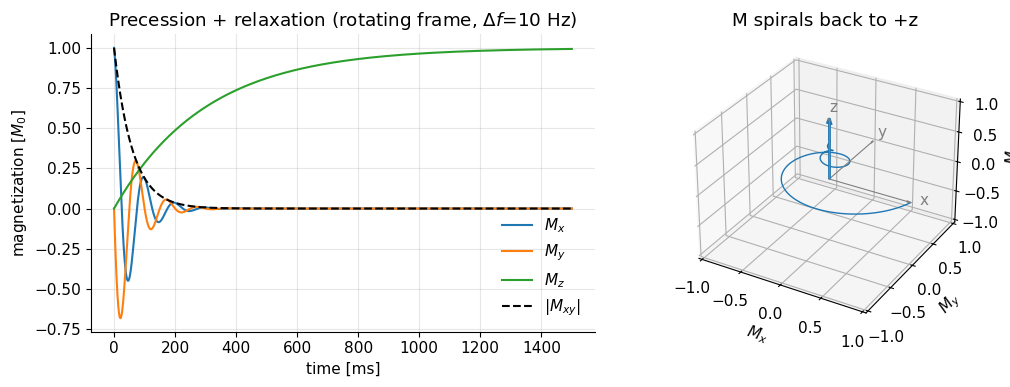

In [9]:
t, M = mt.bloch_simulate(n_steps=1500, dt=1e-3, M_init=[1, 0, 0], T1=0.3, T2=0.06, df=10)
fig = plt.figure(figsize=(11, 4))
ax1 = fig.add_subplot(1, 2, 1)
mt.plot_magnetization(t, M, ax=ax1, components="xyza", title="Precession + relaxation (rotating frame, $\\Delta f$=10 Hz)")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
mt.plot_magnetization_3d(M[:, 0, :], ax=ax2, title="M spirals back to +z")
plt.tight_layout(); plt.show()

*Interpretation:* the transverse part (dashed $|M_{xy}|$) is gone after ~200 ms, while $M_z$ takes ~1 s to get back
to $M_0$. The tip of $\vec M$ spirals inwards and upwards, ending at $[0,0,1]$.

### $T_2^*$ and the spin echo

In a real scanner the field is never perfectly uniform: tiny imperfections of the magnet and, more importantly, the
different magnetic properties of tissue, air and bone (**susceptibility**) make $B_0$ vary by parts per million within a
single voxel. Spins in that voxel then precess at slightly different frequencies, fan out, and their sum $M_{xy}$ shrinks
*faster* than $T_2$ alone predicts. The effective decay time is $T_2^*$:

$$\frac{1}{T_2^*} = \frac{1}{T_2} + \frac{1}{T_2'} .$$

*In words:* decay rates add: the "random" $T_2$ dephasing and the "static field spread" dephasing (time constant $T_2'$)
both remove signal, so $T_2^* \le T_2$.

> **🧭 Intuition (runners):** runners start together but run at slightly different (constant) speeds, so they spread out.
> If everybody turns around at time $TE/2$ and runs back at the same speed, they all arrive at the start line together at
> $TE$. A **180° refocusing pulse** does exactly that to the spins: it flips the fan so the fast ones are behind, and
> the magnetization re-groups into a **spin echo**. Only the static spread ($T_2'$) can be undone — the random $T_2$
> part cannot.

The simulation: 500 spins with random off-resonance (spread 20 Hz), $T_2 = 100$ ms. At $t = 25$ ms we apply an
instantaneous 180° rotation about $x$; we then watch the magnitude of the *average* transverse magnetization.

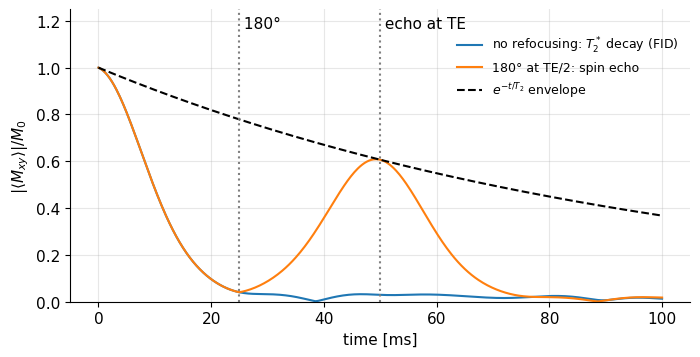

In [10]:
rng = np.random.default_rng(1)
n_spins = 500
df_spread = rng.normal(0, 20, n_spins)            # off-resonance of each spin [Hz]
T2 = 0.100                                        # [s]
dt = 2e-4                                         # 0.2 ms steps
TE = 0.050                                        # echo time [s]

# 1) free precession from M along x (just after a 90 deg pulse) until TE/2
t1, Ma = mt.bloch_simulate(n_steps=int(TE/2/dt), dt=dt, M_init=[1, 0, 0], T2=T2, df=df_spread)
# 2) instantaneous 180 deg pulse about x: rotate by pi using a strong field along x for 1 us
b180 = mt.b1_for_flip(np.pi, 1e-6)
M_after = mt.bloch_rotate(Ma[-1], 1e-6, [b180, 0, 0])
# 3) free precession again until 2*TE
t2, Mb = mt.bloch_simulate(n_steps=int(1.5*TE/dt), dt=dt, M_init=M_after, T2=T2, df=df_spread)

t_all = np.concatenate([t1, t2[1:] + t1[-1]])
M_all = np.concatenate([Ma, Mb[1:]])
signal = np.abs(M_all[:, :, 0].mean(1) + 1j*M_all[:, :, 1].mean(1))   # |average Mxy|

# Same spins but without the 180 deg pulse (pure T2* decay) for comparison
t3, Mc = mt.bloch_simulate(n_steps=len(t_all)-1, dt=dt, M_init=[1, 0, 0], T2=T2, df=df_spread)
fid = np.abs(Mc[:, :, 0].mean(1) + 1j*Mc[:, :, 1].mean(1))

plt.figure(figsize=(8, 3.8))
plt.plot(t3*1e3, fid, label="no refocusing: $T_2^*$ decay (FID)")
plt.plot(t_all*1e3, signal, label="180° at TE/2: spin echo")
plt.plot(t_all*1e3, np.exp(-t_all/T2), "k--", label="$e^{-t/T_2}$ envelope")
plt.axvline(TE/2*1e3, color="gray", ls=":"); plt.axvline(TE*1e3, color="gray", ls=":")
plt.text(TE/2*1e3, 1.17, " 180°"); plt.text(TE*1e3, 1.17, " echo at TE")
plt.xlabel("time [ms]"); plt.ylabel(r"$|\langle M_{xy}\rangle|/M_0$")
plt.legend(loc="upper right", bbox_to_anchor=(1, 0.95), fontsize=9); plt.ylim(0, 1.25); plt.show()

*Interpretation:* without refocusing, the net signal (the **free induction decay**, FID) vanishes within ~20 ms
($T_2^*$). With the 180° pulse, the spins re-phase and the signal comes back at $t = TE$ — not to 1, but to the
$e^{-TE/T_2}$ envelope: the spin echo recovers the $T_2'$ loss but not the true $T_2$ loss.
Echoes are central to MRI: signals are measured as **gradient echoes** or **spin echoes** (P1.3, P1.4).

➡️ **Go deeper:** [A2 Bloch Equation](../pass2_deep_dive/A2_Bloch_Equation.ipynb) (relaxation terms) · [A3 In Vivo Spin Physics](../pass2_deep_dive/A3_In_Vivo_Spin_Physics.ipynb) (susceptibility, chemical shift) · [D1 Basic Contrast Mechanisms](../pass2_deep_dive/D1_Basic_Contrast_Mechanisms.ipynb) (why tissues differ) · [D3 Gradient and Spin Echoes](../pass2_deep_dive/D3_Gradient_and_Spin_Echoes.ipynb) · [RM1 ODEs for MRI](../refreshers/RM1_ODEs_for_MRI.ipynb)

## 7. Signal reception: a rotating magnet induces a voltage

A magnet that moves near a wire loop changes the magnetic flux through the loop, and a changing flux induces a voltage
(**Faraday's law of induction**: the same principle as a bicycle dynamo or an electric guitar pickup). The precessing
transverse magnetization $M_{xy}$ is a magnet rotating at $f_0$, so a **receive coil** placed near the body picks up a
voltage oscillating at $f_0$: the MRI signal $s(t)$. Only $M_{xy}$ contributes — $M_z$ is static and induces nothing.

> **🧭 Intuition (radio):** the body becomes a weak radio station broadcasting at 127.7 MHz (at 3 T) for a few tens
> of milliseconds after each excitation. The receive coil and electronics are a very sensitive radio tuned to that
> station.

Below: the lab-frame signal from a decaying, precessing magnetization (again slowed down to $f_0 = 200$ Hz, with
$T_2^* = 30$ ms), and the **demodulated** signal — what the receiver electronics actually deliver after "mixing down" by
$f_0$: just the slowly varying envelope, i.e. $M_{xy}$ in the rotating frame.

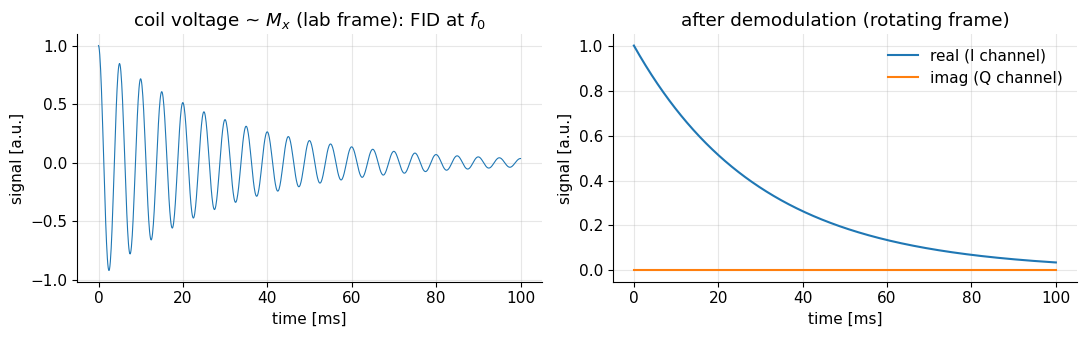

In [11]:
f0_toy = 200.0                                         # scaled-down Larmor frequency [Hz]
dt = 1e-4
t, M = mt.bloch_simulate(n_steps=1000, dt=dt, M_init=[1, 0, 0], T2=0.030, B0=f0_toy/mt.GAMMA_BAR)
Mxy_lab = M[:, 0, 0] + 1j*M[:, 0, 1]                   # complex transverse magnetization in the lab frame
Mxy_rot = Mxy_lab * np.exp(+1j*2*np.pi*f0_toy*t)        # demodulate: undo the e^{-i w0 t} rotation

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(t*1e3, Mxy_lab.real, lw=0.8); ax[0].set_title("coil voltage ~ $M_x$ (lab frame): FID at $f_0$")
ax[1].plot(t*1e3, Mxy_rot.real, label="real (I channel)"); ax[1].plot(t*1e3, Mxy_rot.imag, label="imag (Q channel)")
ax[1].set_title("after demodulation (rotating frame)"); ax[1].legend()
for a in ax: a.set_xlabel("time [ms]"); a.set_ylabel("signal [a.u.]")
plt.tight_layout(); plt.show()

*Interpretation:* the raw coil signal oscillates at $f_0$ inside an $e^{-t/T_2^*}$ envelope. After demodulation, only
the envelope remains (here real-valued because the spins are exactly on resonance). Receivers record two channels
("I" and "Q", in-phase and quadrature) which together form the complex signal — this is why MRI data are complex numbers.

How big is this signal? Very small: the signal from a 1 mm³ voxel at 3 T is of the order of **tens of nanovolts**, and
the whole excited slice gives at most microvolts to a millivolt at the peak of an echo. It competes with **thermal noise**
from the patient's body, which is electrically conducting and therefore "hisses" at all radio frequencies. Most of the
engineering of the receive chain (P1.2) is about not adding any more noise on top of that.

> **🔧 Engineering reality:** To receive nanovolt-level signals next to a transmitter that just blasted kilowatts of RF,
> the scanner room is a **Faraday cage** (RF-shielded room), receive coils are detuned during transmission, and the first
> amplifier (preamplifier) sits right on the coil and adds less than ~1 dB of noise.

The complete MRI signal from an object is the sum (integral) of the contributions of all its voxels. If every voxel
precessed at the same frequency, we could not tell them apart. **Making the frequency depend on position** with
magnetic field gradients is the key to imaging (P1.3).

➡️ **Go deeper:** [B2 Magnetic Fields in MRI](../pass2_deep_dive/B2_Magnetic_Fields_in_MRI.ipynb) (reception, reciprocity) · [B5 RF System and Receive Chain](../pass2_deep_dive/B5_RF_System_and_Receive_Chain.ipynb) · [C2 MRI Signal Equation](../pass2_deep_dive/C2_MRI_Signal_Equation.ipynb) · [RP2 Induction & RF](../refreshers/RP2_Induction_and_RF.ipynb)

## 8. Try it yourself (optional, interactive)

Change $T_1$, $T_2$, the off-resonance and the flip angle and watch the magnetization. (Widgets only work in a live
notebook; the static figures above show the default case.)

In [ ]:
try:
    from ipywidgets import interact, FloatSlider

    def explore(flip_deg=90, T1_ms=800, T2_ms=80, df_Hz=10):
        th = np.deg2rad(flip_deg)
        M_start = [0, np.sin(th), np.cos(th)]          # after a pulse about x (left-handed): z -> +y
        t, M = mt.bloch_simulate(n_steps=1000, dt=2e-3, M_init=M_start, T1=T1_ms*1e-3, T2=T2_ms*1e-3, df=df_Hz)
        fig = plt.figure(figsize=(11, 4))
        mt.plot_magnetization(t, M, ax=fig.add_subplot(1, 2, 1), components="xyza")
        mt.plot_magnetization_3d(M[:, 0, :], ax=fig.add_subplot(1, 2, 2, projection="3d"))
        plt.show()

    interact(explore, flip_deg=FloatSlider(min=0, max=180, step=5, value=90),
             T1_ms=FloatSlider(min=100, max=4000, step=50, value=800),
             T2_ms=FloatSlider(min=10, max=500, step=10, value=80),
             df_Hz=FloatSlider(min=-20, max=20, step=1, value=10))
except ImportError:
    print("ipywidgets not available - skip this cell")

(Interactive widget cell: run this cell yourself in Jupyter to get the sliders.)


For an excellent browser simulator of a "compass needle" in a magnetic field (resonance, excitation, precession,
relaxation), try [CompassMR](https://www.drcmr.dk/CompassMR/) and the [DRCMR Bloch simulator](http://drcmr.dk/BlochSimulator/).

## Key takeaways

* MRI measures the **net magnetization** $\vec M$ of hydrogen nuclei (mostly water and fat), not individual spins.
* **Polarization** by $B_0$ is tiny (≈ 10 ppm at 3 T, $\mu_0 M_0 \approx 12$ nT) but involves enormous numbers of spins; it grows ∝ $B_0$.
* Tipped magnetization **precesses** at the Larmor frequency $f_0=\bar\gamma B_0$ = 42.58 MHz/T × $B_0$ (127.7 MHz at 3 T), clockwise seen from $+z$.
* An RF pulse at $f_0$ **excites** (tips) $\vec M$ by the flip angle $\theta=\gamma B_1 T_{rf}$; off-resonant spins are hardly affected (**resonance**).
* **Relaxation:** $M_z$ recovers with $T_1$ (seconds), $M_{xy}$ decays with $T_2$ (tens of ms); field inhomogeneity adds dephasing ($T_2^*$), which a 180° pulse refocuses into a **spin echo**.
* A receive coil detects the precessing $M_{xy}$ by induction; the signal is a complex, demodulated, nanovolt-to-microvolt voltage.
* Tissue differences in $M_0$, $T_1$ and $T_2$ are the origin of MRI contrast.

## Check your understanding

**1.** What is the Larmor frequency of ¹H at 1.5 T and at 7 T? What would it be for ²³Na at 3 T?

<details><summary>Answer</summary>

$f_0 = \bar\gamma B_0$: 42.58 MHz/T × 1.5 T = 63.9 MHz; × 7 T = 298 MHz. For ²³Na, $\bar\gamma$ = 11.26 MHz/T, so at 3 T
$f_0$ = 33.8 MHz — a coil tuned for protons would not work.

</details>

**2.** Polarization at 3 T is only ~10 ppm. Why do we still get a usable signal?

<details><summary>Answer</summary>

Because the number of protons is enormous (~$7\times10^{19}$ per mm³ of water), so even 10 ppm leaves ~$7\times10^{14}$
"surplus" spins per mm³. In addition, the signal is detected at a known frequency with a narrow-band, low-noise receiver.

</details>

**3.** Right after a 90° pulse, which component of $\vec M$ produces the signal, and which component is zero?

<details><summary>Answer</summary>

The transverse component $M_{xy}$ (magnitude $M_0$) precesses and induces the signal; $M_z = 0$. $M_z$ then regrows with
$T_1$, but a static $M_z$ never induces a voltage.

</details>

**4.** A tissue has $T_2 = 80$ ms. What fraction of the transverse magnetization is left at $TE = 80$ ms in a spin echo?
Would a gradient echo at the same TE give more or less signal?

<details><summary>Answer</summary>

$e^{-80/80} = e^{-1} \approx 0.37$. A gradient echo decays with $T_2^* < T_2$, so it gives *less* signal at the same TE.

</details>

**5.** Why does an RF pulse that is 1 kHz off resonance hardly tip the magnetization, even though 1 kHz is only
0.0008 % of 127.7 MHz?

<details><summary>Answer</summary>

What matters is not the relative detuning but how it compares with the strength of the RF field. In the rotating frame
a detuning $\Delta f$ acts like an extra static field along $z$ of size $\Delta f/\bar\gamma$ = 1000 Hz / 42.58 MHz/T ≈ 23 µT,
which is about four times larger than $B_1$ = 5.87 µT. The magnetization therefore precesses about an effective field
that is tilted only ~14° from $z$ and never gets far from $z$ — like pushing a swing out of rhythm. Equivalently: the
pulse's bandwidth is only ~$1/T_{rf}$ ≈ 1 kHz.

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapters "Introduction", "Key MRI Concepts", "Spin Physics" and "Bloch Equation".
Changes: rewritten as an intuitive overview; added numerical polarization/magnetization estimates, Python resonance, relaxation, spin-echo and reception simulations, and full symbol definitions; corrected $I_Z \to I$, Boltzmann constant written $k_B$, $T_1/T_2$ described as time constants (not rates).*